# Comparing tTEM with tTEM

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *
from anemone.forwards import *

In [2]:
from libaarhusxyz import GEX
import plog

In [3]:
gex = GEX("TX11_3x3_1_turn.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


In [4]:
x,y = gex.General['TxLoopPoint'][:, 0], gex.General['TxLoopPoint'][:, 1]
x,y = np.append(x, x[0]),               np.append(y, y[0])
z   = np.ones_like(x)*abs(gex.General['TxCoilPosition'][2])
tx  = Loop(x,y,z)
rx  = Receiver(*abs(gex.General['RxCoilPosition']))

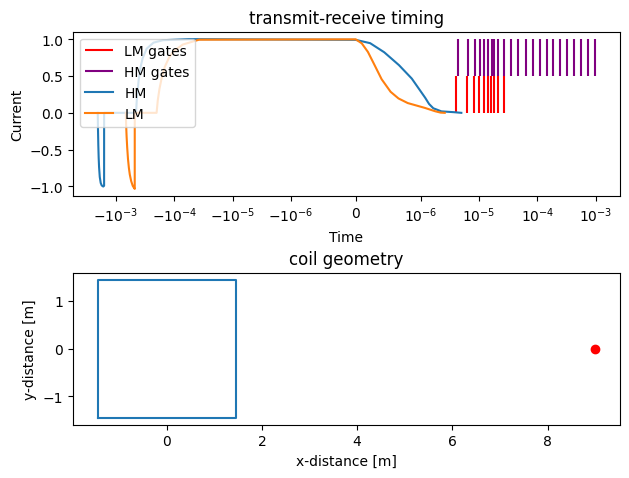

In [5]:
fig,axs=plt.subplots(2,1)
gex.plot(ax=axs[0])
axs[1].plot(tx.x, tx.y)
axs[1].plot(rx.x, rx.y, 'ro')
axs[1].set_aspect('equal')
axs[1].set_xlabel('x-distance [m]')
axs[1].set_ylabel('y-distance [m]')
axs[1].set_title('coil geometry')
axs[0].set_title('transmit-receive timing')
plt.tight_layout()

In [7]:
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

fwr0 = ForwardGeomOp(tx, rx, hmgates, waveform=HMwv, filterfunc=recfilters)
fwr3 = Forward3(tx, rx, hmgates, waveform=HMwv, filterfunc=recfilters)

\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [8]:
res = np.array([10, 200, 20])
thick1 = np.linspace(0.1, 5, 50)

In [9]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])

In [16]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
rho = torch.from_numpy(res)[:, None]
thick = torch.from_numpy(thick_stack)
lgs = [plog.Log(np.log10(res), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

In [17]:
data0 = fwr0(rho, thick)

In [18]:
data3 = fwr3(rho, thick)

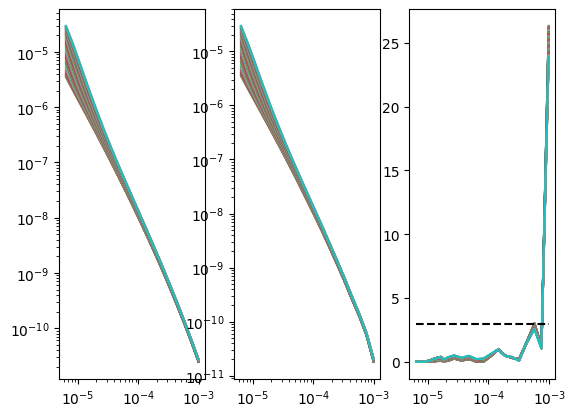

In [19]:
fig,axs = plt.subplots(1,3)
axs[0].loglog(fwr0.times, data0.T);
axs[1].loglog(fwr3.times, data3.T);

axs[2].semilogx(fwr3.times, (100*torch.abs((data0-data3)/data0)).T)
axs[2].semilogx(fwr3.times, 3*torch.ones_like(fwr3.times), 'k--')

In [21]:
%%timeit
data0 = fwr0(rho, thick)

224 ms ± 9.81 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [22]:
%%timeit
data3 = fwr3(rho, thick)

41.7 ms ± 1.87 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
